# DV1583 - Tree Motion User Study Analysis

## Imports, loading and cleaning

In [100]:
# Module imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Plot style
sns.set(style="whitegrid")

In [99]:
# Load CSV

# REPLACE TEST WITH SET A
df_A = pd.read_csv("TreeSetA.csv", encoding="cp1252") # Windows encoding for latin.
df_A["form_id"] = "A" # Tag

df_B = pd.read_csv("TreeSetB.csv", encoding="cp1252")
df_B["form_id"] = "B" # Tag

df_C = pd.read_csv("TreeSetC.csv", encoding="cp1252")
df_C["form_id"] = "C" # Tag

df_D = pd.read_csv("TreeSetD.csv", encoding="cp1252")
df_D["form_id"] = "D" # Tag

df_E = pd.read_csv("TreeSetE.csv", encoding="cp1252")
df_E["form_id"] = "E" # Tag

def clean_dataframe(df):
    df.columns = df.columns.str.strip()

    drop_cols = [
        "Starttid", "Slutförandetid", "E-post", "Namn",
        "I hereby agree to participate in this study voluntarily. I have read the explanation of the study, I understand that my response will be anonymous, and I may withdraw at any time without providing a r",
        "DEMO - Rate how natural the motion of the tree appears to be..The motion of the tree felt..."
    ]
    df = df.drop(columns=drop_cols)

    df = df.rename(columns={
        "What is your gender?": "gender",
        "What is your age group?": "age_group",
        "How familiar are you with video games or other computer-generated visual content (e.g 3D animations, VFX, or other digital graphics)?": "familiarity",
        "Were you in a relatively distraction-free environment during the study?": "distraction_free",
        "Did the videos play smoothly without lag or stuttering?": "video_smooth",
        "Was the visual quality of the videos sufficient for you to judge the motions?": "video_quality"
    })
    
    new_columns = {}

    for col in df.columns:
        col_clean = col.strip()

        match_rating = re.search(r"Clip\s*(\d+).*felt", col_clean, re.IGNORECASE)
        match_text   = re.search(r"Clip\s*(\d+).*What made", col_clean, re.IGNORECASE)

        if match_rating:
            clip_num = match_rating.group(1)
            new_columns[col] = f"clip_{clip_num}_rating"
        elif match_text:
            clip_num = match_text.group(1)
            new_columns[col] = f"clip_{clip_num}_comment"

    df = df.rename(columns=new_columns)

    return df

df_A = clean_dataframe(df_A)
df_B = clean_dataframe(df_B)
df_C = clean_dataframe(df_C)
df_D = clean_dataframe(df_D)
df_E = clean_dataframe(df_E)


In [140]:
# Combine forms
df_all = pd.concat([df_A, df_B, df_C, df_D, df_E], ignore_index=True)

# Melt all data
rating_cols = [col for col in df_all.columns if "_rating" in col]

id_cols = ["Id", "form_id", "gender", "age_group",
    "familiarity", "distraction_free",
    "video_smooth", "video_quality"]

df_long = df_all.melt(id_vars=id_cols, value_vars=rating_cols, var_name="clip", value_name="rating")

df_long["clip_num"] = df_long["clip"].str.extract(r"(\d+)").astype(int)

# Load clip order sheet for mapping answers
mapping_sheets = pd.read_excel("clipMapping.xlsx", sheet_name=None)

mapping_list = []

for sheet_name, df_map in mapping_sheets.items():
    # Form ID based on sheet name
    if "A" in sheet_name:
        form_id = "A"
    elif "B" in sheet_name:
        form_id = "B"
    elif "C" in sheet_name:
        form_id = "C"
    elif "D" in sheet_name:
        form_id = "D"
    elif "E" in sheet_name:
        form_id = "E"
    else:
        continue

    df_map["form_id"] = form_id
    mapping_list.append(df_map)

# Combine sheets
mapping = pd.concat(mapping_list, ignore_index=True)

mapping = mapping.rename(columns={"ClipOrder" : "clip_num"})

# Convert Likert ratings to numbers
likert_map = {
    "Very unnatural": 1,
    "Unnatural": 2,
    "Neutral": 3,
    "Natural": 4,
    "Very natural": 5
}

df_long["rating"] = df_long["rating"].str.strip()
df_long["rating_num"] = df_long["rating"].map(likert_map)

df_long = df_long.merge(mapping, on=["form_id", "clip_num"], how="left")

# DEBUG CORNER FOR CONTROLLING DATA
# df_long.info()
# df_long.head()
# df_long["WindModel"].isna().sum()

# df_long["clip_num"].unique()
# mapping["clip_num"].unique()

#df_long["form_id"].unique()
#mapping["form_id"].unique()

# df_long.groupby("WindModel")["ClipID"].nunique()

## Overview - Gender, age group, and familiarity

In [152]:
def summary_table(col):
    return pd.DataFrame({
        "count": df_all[col].value_counts(),
        "percent": df_all[col].value_counts(normalize=True) * 100
    })

summary_table("gender")

,count,percent
gender,,
Man,28,77.777778
Woman,5,13.888889
Prefer not to say,2,5.555556
Non-binary / Other,1,2.777778


In [153]:
summary_table("age_group")

,count,percent
age_group,,
25-34,17,47.222222
18-24,16,44.444444
35-44,3,8.333333


In [154]:
summary_table("familiarity")

,count,percent
familiarity,,
Very familiar,21,58.333333
Extremely familiar,12,33.333333
Moderately familiar,3,8.333333


In [176]:
# Optional comments regarding what made the motion feel natural / unnatural
comment_cols = [col for col in df_all.columns if "_comment" in col]

# comments = df_all[comment_cols].values.flatten()

# comments = pd.Series(comments)

df_comments = df_all.melt(
    id_vars=["Id", "form_id"],
    value_vars=comment_cols,
    var_name="clip",
    value_name="comment"
)

df_comments["clip_num"] = df_comments["clip"].str.extract(r"(\d+)").astype(int)

df_comments = df_comments.dropna(subset=["comment"])
df_comments = df_comments[df_comments["comment"].str.strip() != ""]

df_comments = df_comments.merge(mapping, on=["form_id", "clip_num"], how="left")

for wm in sorted(df_comments["WindModel"].unique()):
    for s in sorted(df_comments["Setting"].unique()):
        subset = df_comments[(df_comments["WindModel"] == wm) & (df_comments["Setting"] == s)]
        
        print(f"\n--- Model {wm}, Setting {s} ---")
        for c in subset["comment"].head(10):
            print("-", c)


--- Model 1, Setting 1 ---
- The leaves move much less than the tree, making the animation feel too rigid.
- The subtle movements of this is what you would see in real life
- Outer branches are too rigid.
- Too slow for such big movement
- It is more natural since there is not much wind happening, so less things go wrong.
- Very stale.
- The pattern feels a bit too homogeneous, but also not too noticeable due to the "weak wind"
- Wish the trunk didn't move at all
- The movement is too slow.
- Looks like the tree is way too in sync and like it is breathing rather than being affected by wind

--- Model 1, Setting 2 ---
- The tree moves more like a unit than independant leaves and branches
- Slower movements and the trunk moved in unison at a good amount
- The motion of the wind grabbing and pulling the leaves that then pull on the branches and that the trunk is mostly still gives it it's natural feeling. Tho the branches still feel a bit stiff compared to the trunk.
- The leaves looks l

## Statistics - Mean, median and distribution of wind models

In [141]:
wm_summary =  df_long.groupby("WindModel")["rating_num"].agg(["mean", "median", "std", "count"])
wm_summary

,mean,median,std,count
WindModel,,,,
1,2.558642,2.0,1.206132,324
2,3.407407,4.0,1.211685,324
3,3.629630,4.0,1.063838,324


### This table...

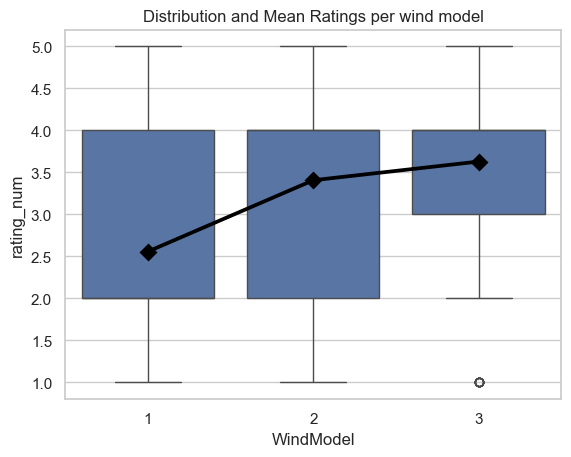

In [155]:
# COMBINED MEAN AND BOXPLOT
plt.figure()
sns.boxplot(data=df_long, x="WindModel", y="rating_num")

sns.pointplot(data=df_long, x="WindModel", y="rating_num", estimator=np.mean, errorbar=None, color="black", markers="D")

plt.title("Distribution and Mean Ratings per wind model")
plt.savefig("figures/windmodel_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

### Distribution and Mean ratings per wind model

Distribution of perceived naturalness ratings for each wind model using a boxplot, with the mean value as a point marker with lines between.

The boxplots illustrates the median, interquartile (middle 50%), and potential outliers. Gives insight into spread and variability of participant responses. Mean values are included to emphasize comparison between wind models.

The results indicate that wind model 1 (sinusoidal) generally received lower ratings, suggesting less natural motion. Wind model 2 (scalar noise field) and 3 (Vector field) show higher central tendencies, indicating more natural perceived motion. While wind model 3 has the highest mean rating, the overlap in distributions between 2 and 3 suggests that their perceived naturalness is relatively similar.

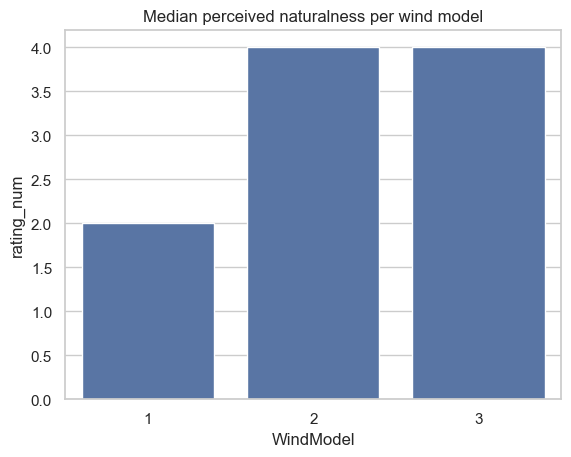

In [156]:
# MEDIAN PLOT
plt.figure()
sns.barplot(data=df_long, x="WindModel", y="rating_num", estimator=np.median, errorbar=None)
plt.title("Median perceived naturalness per wind model")
plt.savefig("figures/windmodel_medianplot.png", dpi=300, bbox_inches="tight")
plt.show()

### Median perceived naturalness per wind model

Shows the median rating for each model.

Since Likert-scale is ordinal, the median provides a more appropiate measure of tendency than the mean. The results show that wind model 1 is considered "unnatural", while both model 2 and 3 is considered "natural".

This indicates a clear difference between model 1 and the other models, while the difference between model 2 and 3 is less obvious when considering median values alone.

### Statistics - Mean, median and distribution of wind model settings

In [139]:
# MEAN, MEDIAN AND STANDARD DEVIATION OF SETTINGS PER WIND MODEL
df_long.groupby(["WindModel", "Setting"])["rating_num"].agg(["mean", "median", "std"])

mean  median       std
WindModel Setting                            
1         1        2.935185     3.0  1.129661
          2        2.861111     2.5  1.179722
          3        1.879630     2.0  1.011315
2         1        3.972222     4.0  0.890850
          2        3.509804     4.0  1.123512
          3        2.780702     2.0  1.267419
3         1        3.731481     4.0  1.010288
          2        3.759259     4.0  0.984652
          3        3.398148     4.0  1.159599

### Ratings by wind model and settings

The table above presents the mean, median, and standard deviation of perceived naturalness ratings grouped by both wind model and settings.

Here, *setting* referes to variations in parameter values controlling the intensity of the wind effect, and not differences in model complexity.

This allows for a more detailed analysis of how changes in motion intensity influence percieved naturalness within each model.

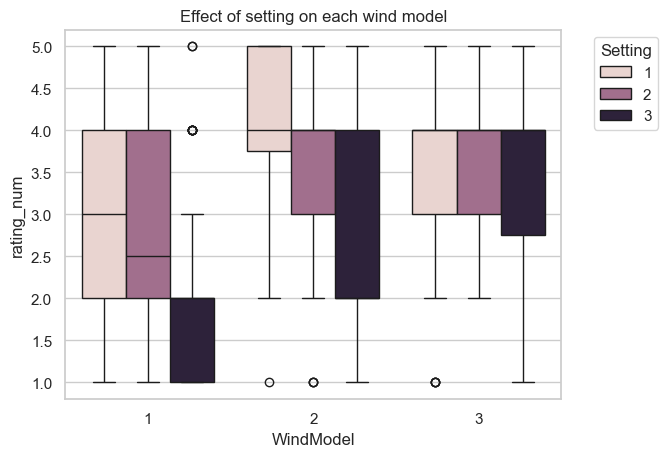

In [157]:
# BOXPLOT FOR EACH WIND MODEL SETTING
# sns.boxplot(data=df_long, x="Setting", y="rating_num", hue="WindModel")
sns.boxplot(x="WindModel", y="rating_num", hue="Setting", data=df_long)
plt.title("Effect of setting on each wind model")
plt.legend(title="Setting", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.savefig("figures/wmSettings_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

### Effect of settings on each wind model

This boxplot illustrates how percieved naturalness varies across different parameter settings for each wind model.

The results show how variations in wind strength influence participant ratings within each model. This helps identify if the models perform consistently across different conditions, or if they depend in the intensity of the applied motion.

There are a couple of outliers, seen particularly on model 1 setting 3, model 2 setting 1 and 2, and model 3 setting 1. This indicates that individual perceptions vary, with some participants rating the motions as significantly more or less natural than the general trend.

In [131]:
# KRUSKAL-WALLIS ANALYSIS

from scipy.stats import kruskal

results = []

for wm in sorted(df_long["WindModel"].unique()):
    groups = [
        g["rating_num"].values
        for _, g in df_long[df_long["WindModel"] == wm].groupby("Setting", sort=True)
    ]
    stat, p = kruskal(*groups)

    results.append({"WindModel": wm, "H_statistic": stat, "p_value": p, "Significant (p < 0.05)": p < 0.05})

df_results = pd.DataFrame(results)

df_results["Significant"] = df_results["p_value"].apply(
    lambda x: "Yes" if x < 0.05 else "No"
)

def format_p(p):
    if p < 0.001:
        return "< 0.001"
    else:
        return f"{p:.3f}"

df_results["p_value_formatted"] = df_results["p_value"].apply(format_p)

df_results = df_results.drop(columns=["Significant (p < 0.05)", "p_value"])

df_results

,WindModel,H_statistic,Significant,p_value_formatted
0,1,56.298521,Yes,< 0.001
1,2,50.715516,Yes,< 0.001
2,3,6.478743,Yes,0.039


### Statistical Analysis: Effect of setting per wind model

A kruskal Wallis test was conducted to see if differences in percieved naturalness between settings were statistically significant within each wind model. 

As mentioned in earlier plots, the settings represent the different intensity settings for each model.

Results show that the effect of setting is statistically significant for all wind models (p < 0.05), indicating that perceived naturalness varies depending on the wind intensity. The magnitude of this effect differs between models, suggesting that some motion models are more sensitive to parameter changes than others.

In [182]:
# KRUSKAL-WALLIS ACROSS WIND MODELS
results_models = []

for setting in sorted(df_long["Setting"].unique()):
    groups = [
        g["rating_num"].values
        for _, g in df_long[df_long["Setting"] == setting].groupby("WindModel", sort=True)
    ]

    stat, p = kruskal(*groups)

    results_models.append({
        "Setting": setting,
        "H_statistic": stat,
        "p_value": p,
        "Significant (p < 0.05)": p < 0.05
    })

df_models = pd.DataFrame(results_models)

# SAME formatting style as your other table
df_models["Significant"] = df_models["p_value"].apply(
    lambda x: "Yes" if x < 0.05 else "No"
)

df_models["p_value_formatted"] = df_models["p_value"].apply(format_p)

# drop raw columns for clean thesis output
df_models = df_models.drop(columns=["Significant (p < 0.05)", "p_value"])

df_models

,Setting,H_statistic,Significant,p_value_formatted
0,1,50.014607,Yes,< 0.001
1,2,32.618645,Yes,< 0.001
2,3,77.486133,Yes,< 0.001
